# Analiza opisowa danych Veturilo

Materiał do rozdziału raportu „dane i analiza opisowa”: przejazdy, relokacje operatora, rowery poza stacjami, flota i e-rowery.
Dane: `processed/` (najpierw `python -m src.data.build`). Czas w UTC; godzina i dzień tygodnia liczone w czasie warszawskim.

Przejazdy użytkowników bez artefaktów: `type == "user"` oraz bez flag `is_flicker`, `too_fast`, `is_long`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "processed").exists() else Path.cwd().parent
P = ROOT / "processed"
trips = pd.read_parquet(P / "trips.parquet")
reb = pd.read_parquet(P / "rebalancing_observed.parquet")
fleet = pd.read_parquet(P / "fleet_timeseries.parquet")
stations = pd.read_parquet(P / "stations.parquet")
ctx = pd.read_parquet(P / "context_hourly.parquet")
TZ = "Europe/Warsaw"

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "font.size": 10, "legend.frameon": False, "lines.linewidth": 2,
})
DAY_TYPES = {"workday": ("dzień roboczy", BLUE), "saturday": ("sobota", ORANGE), "sunday_holiday": ("niedziela/święto", AQUA)}

user = trips[(trips["type"] == "user") & ~trips["is_flicker"] & ~trips["too_fast"] & ~trips["is_long"]].copy()
loc = user["t_departure"].dt.tz_convert(TZ)
user["date"], user["hour"] = loc.dt.date, loc.dt.hour
day_type = ctx.drop_duplicates("local_date").set_index("local_date")["day_type"]
user["day_type"] = user["date"].map(day_type)
print(f"Przejazdy użytkowników: {len(user):,}; relokacje: {(trips['type'] == 'service').sum():,} rowerów w {len(reb)} grupach")

Przejazdy użytkowników: 31,373; relokacje: 1,191 rowerów w 250 grupach


## 1. Przejazdy w czasie

,przejazdy,godzin danych,typ dnia
date,,,
2026-10-22,224,9,dzień roboczy
2026-10-23,11764,24,dzień roboczy
2026-10-24,9158,24,sobota
2026-10-25,8082,25,niedziela/święto
2026-10-26,2145,11,dzień roboczy


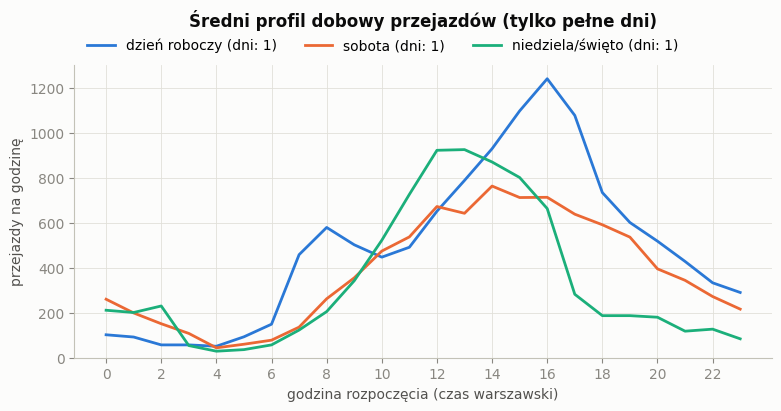

In [2]:
per_day = user.groupby("date").size()
# dni niepełne (poczatek/koniec danych) oznaczamy - liczba przejazdów jest zaniżona
obs_hours = ctx.groupby("local_date").size()
tab = pd.DataFrame({"przejazdy": per_day, "godzin danych": obs_hours.reindex(per_day.index),
                    "typ dnia": [DAY_TYPES.get(day_type.get(d), ("?",))[0] for d in per_day.index]})
display(tab)

full_days = [d for d in per_day.index if obs_hours.get(d, 0) >= 23]
prof = (user[user["date"].isin(full_days)].groupby(["day_type", "hour"]).size()
        / user[user["date"].isin(full_days)].groupby("day_type")["date"].nunique()).unstack(0)
fig, ax = plt.subplots(figsize=(9, 3.8))
for dt_, (lab, c) in DAY_TYPES.items():
    if dt_ in prof:
        n = user[user["date"].isin(full_days) & (user["day_type"] == dt_)]["date"].nunique()
        ax.plot(prof.index, prof[dt_], color=c, label=f"{lab} (dni: {n})")
ax.set(xlabel="godzina rozpoczęcia (czas warszawski)", ylabel="przejazdy na godzinę", xticks=range(0, 24, 2), ylim=(0, None))
ax.set_title("Średni profil dobowy przejazdów (tylko pełne dni)", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3)
plt.show()

## 2. Czas i długość przejazdów

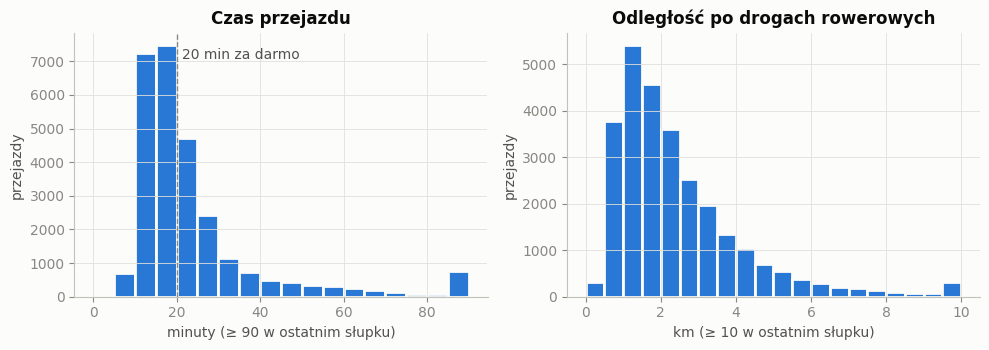

,duration_min,network_km
p10,10.0,0.9
mediana,15.0,2.0
p90,40.0,4.7


Mediana prędkości (dolna granica, bo czas zawyżony o ~5 min): 7.4 km/h; do 20 min: 73% przejazdów


In [3]:
st = user[(user["from_type"] == "station") & (user["to_type"] == "station") & ~user["same_station"]]
dist_col = "network_km" if "network_km" in st and st["network_km"].notna().any() else "distance_km"
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(st["duration_min"].clip(upper=90), bins=np.arange(0, 95, 5), color=BLUE, edgecolor=SURFACE, linewidth=2)
axes[0].axvline(20, color=MUTED, ls="--", lw=1)
axes[0].annotate("20 min za darmo", (20, axes[0].get_ylim()[1] * 0.9), xytext=(4, 0), textcoords="offset points", color=INK2)
axes[0].set(title="Czas przejazdu", xlabel="minuty (≥ 90 w ostatnim słupku)", ylabel="przejazdy")
axes[1].hist(st[dist_col].clip(upper=10), bins=np.arange(0, 10.5, 0.5), color=BLUE, edgecolor=SURFACE, linewidth=2)
axes[1].set(title="Odległość " + ("po drogach rowerowych" if dist_col == "network_km" else "w linii prostej"),
            xlabel="km (≥ 10 w ostatnim słupku)", ylabel="przejazdy")
plt.tight_layout(); plt.show()
q = st[["duration_min", dist_col]].quantile([0.1, 0.5, 0.9]).round(1)
q.index = ["p10", "mediana", "p90"]; display(q)
speed = (st[dist_col] / (st["duration_min"] / 60)).median()
print(f"Mediana prędkości (dolna granica, bo czas zawyżony o ~5 min): {speed:.1f} km/h; "
      f"do 20 min: {(st['duration_min'] <= 20).mean():.0%} przejazdów")

## 3. Relokacje operatora (`rebalancing_observed`)

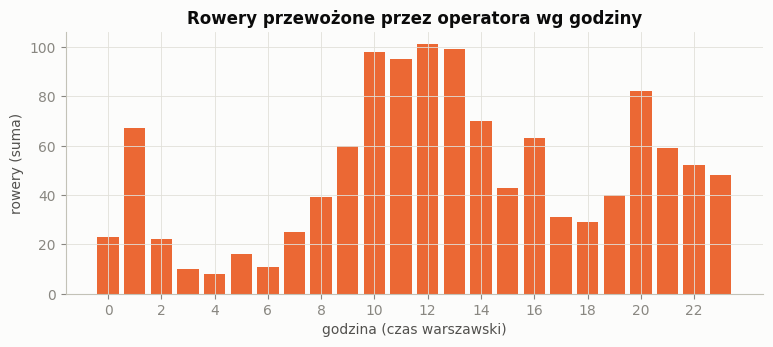

Skąd operator zabiera rowery:


,rowery,stacja
from_station,,
2585802,53,Sobieskiego - Chełmska
2585921,40,Grupy AK Krybar
2585747,33,Myśliwiecka - Rozbrat
4393742,32,Metro Centrum Nauki Kopernik
2585467,28,Belwederska - Gagarina
2585708,26,Książęca - Rozbrat
2585929,25,Plac Hallera - Dąbrowszczaków
2585278,21,OSiR Żoliborz


Dokąd operator przywozi rowery:


,rowery,stacja
to_station,,
2585913,25,Metro Kabaty
2585738,23,Plac Na Rozdrożu
2585838,23,Metro Wilanowska - Dworzec Południowy
2585694,20,Plac Trzech Krzyży
2585888,18,Puławska - Pileckiego
2585422,18,Plac Powstańców Warszawy
2585764,17,Biblioteka Narodowa
2585876,17,Jastrzębowskiego - SGGW


Grupa relokacji: mediana 4 rowerów, czas przewozu mediana 40 min


In [4]:
r = reb.assign(hour=reb["t_departure"].dt.tz_convert(TZ).dt.hour)
fig, ax = plt.subplots(figsize=(9, 3.4))
h = r.groupby("hour")["n_bikes"].sum().reindex(range(24), fill_value=0)
ax.bar(h.index, h.values, color=ORANGE, width=0.8)
ax.set(title="Rowery przewożone przez operatora wg godziny", xlabel="godzina (czas warszawski)", ylabel="rowery (suma)", xticks=range(0, 24, 2))
plt.show()
names = stations.set_index("station_id")["name"]
top = lambda col: (r.groupby(col)["n_bikes"].sum().sort_values(ascending=False).head(8)
                   .rename("rowery").to_frame().assign(stacja=lambda d: d.index.map(names)))
print("Skąd operator zabiera rowery:"); display(top("from_station"))
print("Dokąd operator przywozi rowery:"); display(top("to_station"))
print(f"Grupa relokacji: mediana {r['n_bikes'].median():.0f} rowerów, czas przewozu mediana {r['duration_min'].median():.0f} min")

## 4. Rowery zostawiane poza stacjami (`data/loose`)

Przejazdy kończone poza stacją: 1,129 (3.6%); zaczynane poza stacją: 593 (1.9%)
Rowery poza stacjami w Warszawie jednocześnie: mediana 25, max 48; poza Warszawą: mediana 2


Odległość roweru zostawionego poza stacją od najbliższej stacji: mediana 197 m, p90 574 m


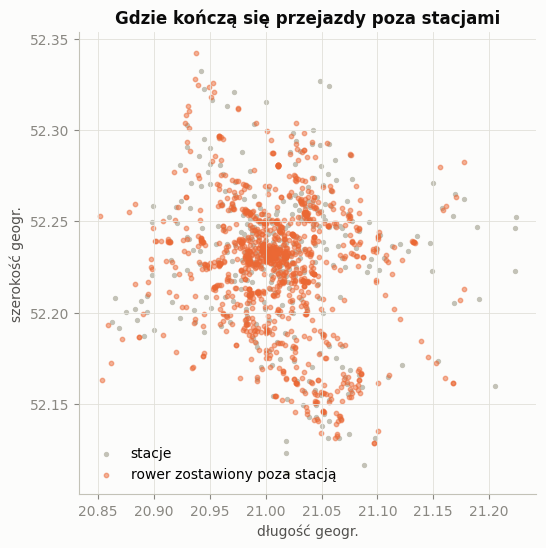

In [5]:
out_ = user[user["to_loose"]]
back = user[user["from_loose"]]
print(f"Przejazdy kończone poza stacją: {len(out_):,} ({len(out_) / len(user):.1%}); "
      f"zaczynane poza stacją: {len(back):,} ({len(back) / len(user):.1%})")
print(f"Rowery poza stacjami w Warszawie jednocześnie: mediana {fleet['loose_warsaw'].median():.0f}, "
      f"max {fleet['loose_warsaw'].max():.0f}; poza Warszawą: mediana {fleet['loose_outside'].median():.0f}")
# jak daleko od najblizszej stacji zostawiane sa rowery
from scipy.spatial import cKDTree
xy = lambda lat, lon: np.column_stack([np.radians(lon) * 6371 * np.cos(np.radians(52.23)), np.radians(lat) * 6371])
tree = cKDTree(xy(stations["lat"], stations["lon"]))
d_km, _ = tree.query(xy(out_["to_lat"], out_["to_lon"]))
print(f"Odległość roweru zostawionego poza stacją od najbliższej stacji: mediana {np.median(d_km) * 1000:.0f} m, "
      f"p90 {np.quantile(d_km, 0.9) * 1000:.0f} m")
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(stations["lon"], stations["lat"], s=8, color=AXIS, label="stacje")
ax.scatter(out_["to_lon"], out_["to_lat"], s=10, color=ORANGE, alpha=0.5, label="rower zostawiony poza stacją")
ax.set(title="Gdzie kończą się przejazdy poza stacjami", xlabel="długość geogr.", ylabel="szerokość geogr.")
ax.set_aspect(1 / np.cos(np.radians(52.23))); ax.legend(loc="lower left"); plt.show()

## 5. Flota w czasie

`fleet_timeseries`: rowery na stacjach, poza stacjami, w drodze (zniknęły < 4 h temu) i poza systemem (> 4 h – zwykle serwis), na tle docelowej floty operatora (`set_point_bikes`). „W drodze > 4 h” rośnie z czasem, bo obejmuje też rowery wycofane do serwisu.

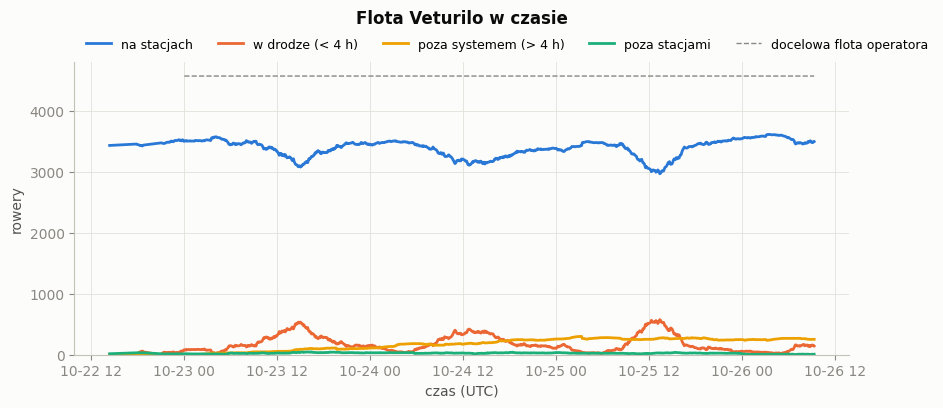

Maks. rowerów w drodze jednocześnie: 575 (Sun 25.10 14:20)


In [6]:
f = fleet.dropna(subset=["in_use"]).set_index("time")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(f.index, f["at_stations"], color=BLUE, label="na stacjach")
ax.plot(f.index, f["in_use"], color=ORANGE, label="w drodze (< 4 h)")
ax.plot(f.index, f["away_long"], color=YELLOW, label="poza systemem (> 4 h)")
ax.plot(f.index, f["loose_warsaw"], color=AQUA, label="poza stacjami")
if "set_point_bikes" in f and f["set_point_bikes"].notna().any():
    ax.plot(f.index, f["set_point_bikes"], color=MUTED, ls="--", lw=1, label="docelowa flota operatora")
ax.set(xlabel="czas (UTC)", ylabel="rowery", ylim=(0, None))
ax.set_title("Flota Veturilo w czasie", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=5, fontsize=9)
plt.show()
print(f"Maks. rowerów w drodze jednocześnie: {f['in_use'].max():.0f} ({f['in_use'].idxmax().tz_convert(TZ):%a %d.%m %H:%M})")

## 6. E-rowery

E-rowery: 8.1% stojących rowerów, ale 19.0% przejazdów → e-rower jest wypożyczany ok. 2.3× częściej niż zwykły


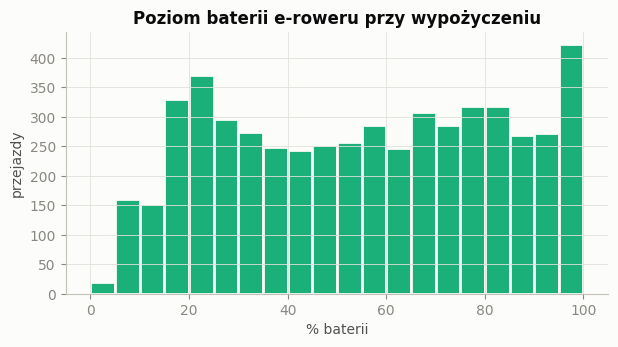

,duration_min,distance_km
is_ebike,,
zwykły,15.0,1.5
e-rower,15.0,1.5


In [7]:
share_trips = user["is_ebike"].mean()
share_fleet = (f["ebikes_parked"] / (f["at_stations"] + f["loose_warsaw"])).median()
print(f"E-rowery: {share_fleet:.1%} stojących rowerów, ale {share_trips:.1%} przejazdów "
      f"→ e-rower jest wypożyczany ok. {share_trips / share_fleet:.1f}× częściej niż zwykły")
e = user[user["is_ebike"] & user["battery_start"].notna()]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(e["battery_start"], bins=np.arange(0, 105, 5), color=AQUA, edgecolor=SURFACE, linewidth=2)
ax.set(title="Poziom baterii e-roweru przy wypożyczeniu", xlabel="% baterii", ylabel="przejazdy")
plt.show()
cmp_ = user[(user["from_type"] == "station") & (user["to_type"] == "station") & ~user["same_station"]]
display(cmp_.groupby("is_ebike")[["duration_min", "distance_km"]].median().rename(index={False: "zwykły", True: "e-rower"}).round(1))

## Wnioski do raportu (uzupełniać po każdym przeliczeniu)

- Profil dobowy: szczyty dnia roboczego vs późniejszy start w weekend – podstawa intensywności λ(godzina, typ dnia).
- Czas przejazdu skupia się poniżej 20 min (darmowy próg cennika) – rozkład czasu w modelu powinien to odwzorować.
- Relokacje: godziny i stacje źródłowe/docelowe = obserwowana strategia operatora (dla Osoby 2 i 3).
- Rowery poza stacjami i rowery poza systemem zmniejszają efektywną flotę – w symulacji flota nie jest stała.
- E-rowery są wypożyczane wyraźnie częściej niż wynika z ich udziału we flocie – osobny strumień popytu.